In [2]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
print("imported")

imported


In [3]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
 
print("Dataset exists:", DATA_DIR.exists())

Dataset exists: True


In [4]:
for path in sorted(DATA_DIR.iterdir()):
    print(f"Dir {path.name}")

Dir glioma
Dir meningioma
Dir notumor
Dir pituitary


In [5]:
subdirectories = sorted(
    path for path in DATA_DIR.iterdir()
    if path.is_dir()
)

print(f"Number of immediate subdirectories: {len(subdirectories)}")

for directory in subdirectories:
    child_directories = [
        path.name for path in directory.iterdir()
        if path.is_dir()
    ]

    print(f"\n{directory.name}/")

    if child_directories:
        for child in sorted(child_directories):
            print(f"    {child}/")
    else:
        print("    No nested directories")

Number of immediate subdirectories: 4

glioma/
    No nested directories

meningioma/
    No nested directories

notumor/
    No nested directories

pituitary/
    No nested directories


In [6]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_dirs = sorted(
    path for path in DATA_DIR.iterdir() if path.is_dir()
)
if not class_dirs:
    raise ValueError("No class folders found, check the dataset path")

class_images = {}
extention_counts = Counter()
for class_dir in class_dirs:
    images = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file() 
        and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    class_images[class_dir.name] = images
    for image_path in images:
        extention_counts[image_path.suffix.lower()] += 1
print("Class distribution")
print("-" * 55)
for class_name, images in class_images.items():
    print(f"{class_name} {len(images)}")

print("Supported image extensions", extention_counts)
print(
    "\n total supported images:", sum(len(images) for images in class_images.values())
)

Class distribution
-------------------------------------------------------
glioma 1621
meningioma 1645
notumor 2000
pituitary 1757
Supported image extensions Counter({'.jpg': 7023})

 total supported images: 7023


In [7]:
all_files = [
    path for path in DATA_DIR.rglob("*")
    if path.is_file()
]
unsupported_files = [
    path for path in all_files
    if path.suffix.lower() not in SUPPORTED_EXTENSIONS
]
unreadable_images = []
for images in class_images.values():
    for image_path in images:
        image = cv2.imread(str(image_path))

        if image is None:
            unreadable_images.append(image_path)
print("Unsupported files:", len(unsupported_files))
print("Unreadable images:", len(unreadable_images))

Unsupported files: 0
Unreadable images: 0


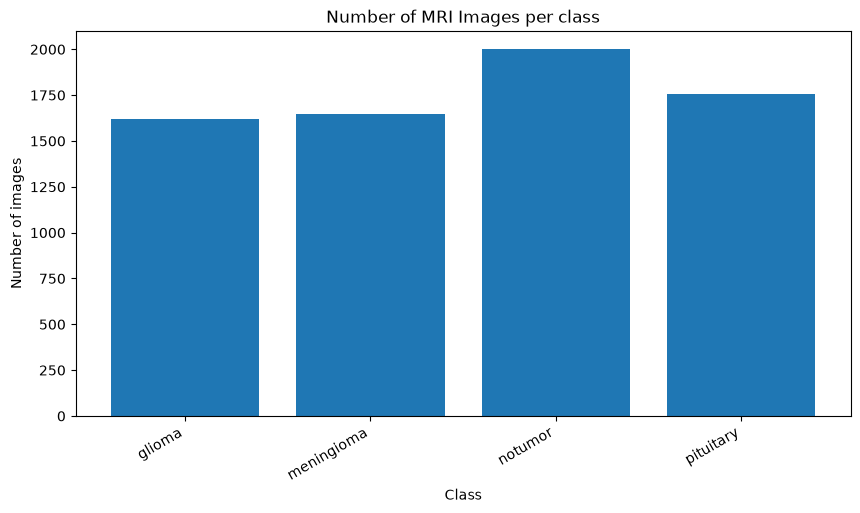

In [10]:
class_names = list(class_images.keys())
class_counts = [
    len(class_images[name])
    for name in class_names
]
plt.figure(figsize=(10, 5))
plt.bar(class_names, class_counts)
plt.title("Number of MRI Images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.show()